In [1]:
import math
import numpy as np
import matplotlib.pyplot as g
import torch
import random
from  graphviz import Digraph
%matplotlib inline

In [35]:
class Scalar:
    # Properties initialize Karnyasathi constructor (CTOR) asto 
    # CTOR is a special function
    # () = Tuple = list of numbers that you cannot change once assigned
    
    
    def __init__(self, value, label='', oprt = '', children = ()):
        # self = Jyane he function call kele ahe to/ti
        self.value = value
        self.label = label
        self.oprt  = oprt
        self.children = children
        self.der = 0.0
        self._backward = lambda: None


    def __add__(self, other):

        # If other is not "Scalar" type then convert it to Scalar type
        other = other if isinstance(other, Scalar) else Scalar(other)
        out = Scalar(self.value + other.value, '', oprt='+', children=(self, other))

        # for back propagation
        def _backward():
            # Addition madhe
            # derivative of output will propagate to both of its operands
            # out = self + other
            # tar, out cha derivative self ani other kade propagate honar ahe
            self.der += 1.0 * out.der # 1.0 is local derivative of x in y = z + x (dy/dx = 1)
            other.der += 1.0 * out.der
            # It is possible that self and other are SAME


        # function assignment
        # Python madhe functions he variables sarkhe treat kele jatat
        # Python madhe functions are "First class citizens"
        out._backward = _backward

        return out

    def __radd__(self, other):
        # what is r ?
        # r = reflected (swapped operands)
        return self + other # Calls __add__

    def __rmul__(self, other): # Reflected multiplication
        return self * other

    def __pow__(self, n):
        out = Scalar(self.value ** n, label='', children=(self,), oprt=f'**{n}')

        def _backward():
            self.der += n * (self.value ** (n-1)) * out.der

        out._backward = _backward
        return out

    def __neg__(self):
        # Implement negation using mul and rmul
        return self * -1
        
    def __sub__(self, other):
        # Implement subtraction using addition + negation
        return self + (-other)

    def __rsub__(self, other):
        return other + (-self)
        
    def __mul__(self, other):
        other = other if isinstance(other, Scalar) else Scalar(other)
        out = Scalar(self.value * other.value, '', oprt='*', children=(self, other))

        def _backward():
            self.der += other.value * out.der  # y = 3 * x =>  dy/dx = 3;  c = a * b then dc/da = b
            other.der += self.value * out.der

        out._backward = _backward

        return out

        # for back propagation

    def relu(self):
        # if value is negative, makes it 0
        # else keep value as-is
        out =  Scalar(0 if self.value < 0 else self.value, '', oprt = 'ReLU', children=(self,))

        def _backward():
            self.der += (out.value > 0) * out.der

        out._backward = _backward
        return out

    def backward(self):
        '''
        What should it do ?
        '''
        visited = set() # nodes from trace function
        topo = list()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v.children:
                    build_topo(child)

                topo.append(v)

        build_topo(self) # jyane call kela tithun start kara

        self.der = 1.0 # dL/dL = 1.0
        for v in reversed(topo):
            v._backward()
            

In [36]:

def trace(root):
    # nodes will act as visited array
    nodes = set() # Expression Graph che nodes 
    edges = set() # Expression Graph chya edges

    def build(v):
        if v not in nodes:
            nodes.add(v)


            for child in v.children:
                edges.add((child,v))
                build(child)

    build(root)
    return nodes, edges
    
class MermaidGraph:
    """Wraps Mermaid source so Jupyter renders it inline, like a graphviz Digraph."""
    def __init__(self, source):
        self.source = source

    def _repr_mimebundle_(self, include=None, exclude=None):
        return {
            'text/vnd.mermaid': self.source,                      # JupyterLab 4.1+ / Notebook 7.1+
            'text/markdown': f"```mermaid\n{self.source}\n```",   # fallback renderer
            'text/plain': self.source,
        }

    def __str__(self):
        return self.source


def draw_mermaid(root, rankdir='LR'):
    nodes, edges = trace(root)

    def esc(s):
        return str(s).replace('"', '#quot;')   # Mermaid's escape for quotes

    lines = [f"flowchart {rankdir}"]

    for n in nodes:
        nid = f"n{id(n)}"
        lines.append(f'    {nid}["{esc(n.label)} | Val {n.value:.4f} | Der {n.der:.4f}"]')
        if n.oprt:
            lines.append(f'    {nid}_op(("{esc(n.oprt)}"))')
            lines.append(f'    {nid}_op --> {nid}')

    for n1, n2 in edges:
        lines.append(f'    n{id(n1)} --> n{id(n2)}_op')

    return MermaidGraph("\n".join(lines))


def draw_graph(root, format='svg', rankdir='LR'):
    nodes, edges = trace(root)
    
    graph = Digraph(
        format=format,
        graph_attr={'rankdir': rankdir, 'bgcolor': 'transparent'},
        node_attr={
            'style': 'filled',
            'fillcolor': '#2d2d2d',
            'color': '#d4d4d4',
            'fontcolor': '#d4d4d4',
            'fontname': 'Helvetica',
        },
        edge_attr={'color': '#d4d4d4'},
    )
    
    for n in nodes:
        graph.node(name=str(id(n)), label = "{ %s | Val %.4f | Der %.4f }" % (n.label, n.value, n.der), shape='record')
        if n.oprt:
            graph.node(name=str(id(n)) + n.oprt, label=n.oprt, fillcolor='#264f78', color='#569cd6', fontcolor='#ffffff')
            graph.edge(str(id(n)) + n.oprt, str(id(n)))
    
    for n1, n2 in edges:
        graph.edge(str(id(n1)), str(id(n2)) + n2.oprt)
    
    return graph



## Call 
Calling a function

use of parantheses ()

add()
multiply()

Neuron class cha CTOR call hoto
CTOR = Jyamule Class cha instance/object tayar hoto

n = Neuron() // Neuron.__init__ = CTOR


a = Scalar (1)
b = Scalar (2)

```
c = a + b  => a.__add__(b) => __add__(self = a, other = b)

+  : Operator (addition)
() : Operator (function call operator)

f(x) = function of x = x is input to f
```

For Neuron class, we want to call / invoke each neuron with one or more inputs (Xs)

n = Neuron(3) # Neuron with 3 inputs

```
x = [1,2,3]


n(x) # n of x = Call Neuron n with input x
     # Use weights and biases inside this Neuron object/instance
     # and apply products + summation + activation

f(x) = x1 * w1 + x2 * w2 + ..... + bias


def fun(): # This is definition of function
    some code
```

fun() # function call
'''

In [96]:
class Neuron:
    def __init__(self, n_inputs, act='relu', initial_bias=None): # CTOR
        self.weights = [Scalar(random.uniform(-1,1), label=f'w{i+1}') for i in range (n_inputs)]
        self.bias = Scalar(random.uniform(-1,1), label='b') if initial_bias == None else Scalar(initial_bias)
        self.act = act # relu
        self.last_pre = None # Debugging purpose
    
    # Implement function call operator "()" for Neuron object
    # so that n(x) will provide us the output of neuron n with input x
    def __call__(self, x):
        # x is of lenght 3 (x is in R^3)
        n = sum(xi * wi for xi, wi in zip(x, self.weights)) + self.bias
        self.last_pre = n.value
        
        if self.act == 'relu':
            return n.relu()

        return n # Linear

    @property # params will be accessible as a data of neuron and not a function
    def params(self):
        # concatenate two lists
        return self.weights + [self.bias]
    

In [97]:
class Layer:
    # Layer of neurons
    # 3 , 4
    def __init__(self, n_inputs, n_outputs, **kwargs): # kwargs : keyword arguments are optional
        self.neurons = [Neuron(n_inputs, **kwargs) for _ in range(n_outputs)]

    def __call__(self, x):
        # List comprehension
        # collect output of each neuron n from list of neurons (self.neurons)
        # n(x) => Calls the Neuron object, collects the output
        outputs = [n(x) for n in self.neurons]
        return outputs[0] if len(outputs) == 1 else outputs

    @property
    def params(self):
        # Get each neuron, and each parameter in each neuron
        return [p for neuron in self.neurons for p in neuron.params]

In [98]:
class MLP:
    '''
    Multi Layer Perceptron
    '''
    def __init__(self, n_inputs, output_layers, act='relu', initial_bias=None):
        # concatenate two lists 3 [4,4,1] => [3,4,4,1]
        # sizes = [3,4,4,1]
        '''
        we need 3 layers (3 is len(output_layers))
                  0  1  2  3
        3 X 4    [3, 4, 4, 1]   => List madhle index[0] ani index[1]
        4 X 4    [3, 4, 4, 1]   => List madhle index[1] ani index[2]
        4 X 1    [3, 4, 4, 1]   => List madhle index[2] ani index[3]
                 s i z e s
        '''
        sizes = [n_inputs] + output_layers
        self.layers = [
            Layer(
                sizes[i], sizes[i+1],
                act=act,
                initial_bias=initial_bias
            )
            for i in range(len(output_layers)) 
        ]

    def __call__(self, x):
        for l in self.layers:
            x = l(x) # => calls layer l with input x

        return x

    @property
    def params(self):
        # How to calculate parameters of this MLP ?
        # l.params will call the @property decorated method of Layer l
        return [p for l in self.layers for p in l.params]
        

In [99]:
# x = [demand, stock, incoming] R^3
# y (order) = max(0, demand - stock - incoming)
xs = [
    [3.0, 1.0, 1.0],   # 3 - 1 - 1 =  1
    [4.0, 1.0, 0.0],   # 4 - 1 - 0 =  3
    [2.0, 2.0, 1.0],   # 2 - 2 - 1 = -1  -> 0
    [5.0, 2.0, 1.0],   # 5 - 2 - 1 =  2
    [1.0, 0.0, 2.0],   # 1 - 0 - 2 = -1  -> 0
]
ys = [1.0, 3.0, 0.0, 2.0, 0.0]

In [100]:
random.seed(2)
nn = MLP(3, [4,4,1]) 

In [101]:
# xs =  array of arrays or array of vectors
# but neuron works on ONE VECTOR AT A TIME
ypred = [nn(x) for x in xs]

In [102]:
for y in ypred:
    print(y.value)

0.9966774430645892
2.5014917864710036
0.9981722528074892
3.1705611571741534
0.7023229175018586


In [103]:
loss = sum((ya - yp)**2 for ya, yp in zip(ys, ypred))

In [104]:
loss.backward()

# Derivative vs Gradient

Gradient ha vector cha asto
Derivative ha expression cha

y = f(x), derivative of y (derivative of f(x)) asa Mhanato

y = x1 * w1 + x2 w2 + x3 w3.....
(composed of vectors)
gradients of vector


In [57]:
'''
xs : initial inputs
ys : their corresponding outputs (actual output)
'''
def compute_loss(nn):
    ypred = [nn(x) for x in xs]
    loss = sum((ya - yp)**2 for ya, yp in zip(ys, ypred))
    return loss

In [105]:
def grad_check(model, h = 1e-5):

    # 1. Compute loss and back propagate gradients
    loss = compute_loss(model)
    for p in model.params:
        p.der = 0.0

    loss.backward()

    # Take some numbers from 41
    print(f"{'param':>5} {'backprop':>10} {'numerical':>10}") 
    for i in [0, 1, 2, 3, 37, 38, 39, 40]:
        p = model.params[i]
        # store the original value of this param
        old = p.value

        p.value = old + h
        loss_plus = compute_loss(model).value
        p.value = old - h
        loss_minus = compute_loss(model).value

        # restore the value
        p.value = old

        numerical_grad = (loss_plus - loss_minus) / (2 * h)
        print(f"{i:5d} {p.der:10.4f} {numerical_grad:10.4f}")
        

In [106]:
grad_check(nn)

param   backprop  numerical
    0     8.2706     8.2706
    1     5.4272     5.4272
    2     3.0640     3.0640
    3     2.3586     2.3586
   37     0.4178     0.4178
   38     0.0000     0.0000
   39     0.0000     0.0000
   40     4.7385     4.7385


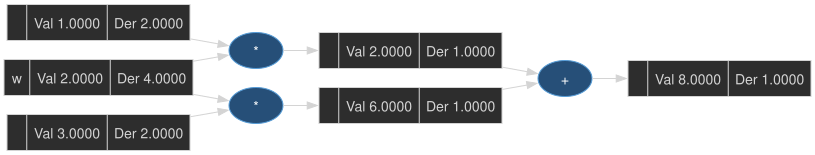

In [107]:
wbug = Scalar(2.0, label='w')
Lbug = wbug * 1.0 + wbug * 3.0
Lbug.backward()
draw_graph(Lbug)




In [108]:
print(wbug.der)

4.0


If the derivative is positive p.der > 0
increasing p will increase the loss
So, decrease p

If the derivative is negative (p.der < 0)
increase p will decrease the loss
So, increase p


In [109]:
# Learning rate
lr = 0.01

loss = compute_loss(nn) # forward pass happens here inside compute_loss
print(f"Loss before : {loss.value}")

for p in nn.params:
    p.der = 0.0
loss.backward()

for p in nn.params:
    p.value += (-1) * p.der * lr
    

loss = compute_loss(nn)
print(f"Loss after  : {loss.value}")



Loss before : 3.1083402277484544
Loss after  : 3.0963351172140094


In [110]:
grad_check(nn)

param   backprop  numerical
    0    -7.8188    -7.8188
    1    -2.0916    -2.0916
    2    -0.1825    -0.1825
    3    -1.9091    -1.9091
   37     0.2951     0.2951
   38     0.0000     0.0000
   39     0.0328     0.0328
   40    -2.0694    -2.0694


In [111]:
loss = compute_loss(nn)
for p in nn.params: p.der = 0.0 # If we don't then derivatives will explode
loss.backward()
for p in nn.params: p.value += (-1) * p.der * lr
print(loss.value)

3.0963351172140094


In [112]:
def train(model, lr=0.01, epochs=500, zero_grad=True):
    loss_history = []
    for step in range(epochs):
        loss = compute_loss(model) # 1. Foward pass
        if zero_grad:
            for p in model.params: p.der = 0.0 # 2. Zero grad
                
        loss.backward()  # 3. Backward propagation
        for p in model.params: p.value += (-1) * p.der * lr # Param update

        loss_history.append(loss.value)

    return loss_history

3.1083402277484544 0.7571822444318534 0.009708130148548488


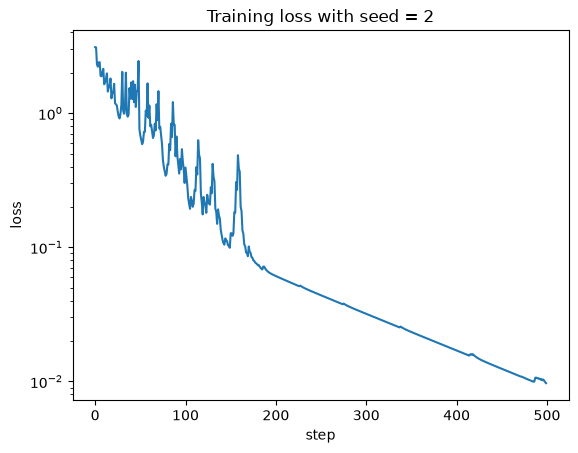

In [113]:
random.seed(2)
nn = MLP(3, [4,4,1])
history = train(nn)
print(history[0], history[49], history[-1])

g.plot(history)
g.yscale('log')
g.xlabel('step')
g.ylabel('loss')
g.title('Training loss with seed = 2')
g.show()

In [114]:
print(history[-1])

0.009708130148548488


In [115]:
print(history[0])

3.1083402277484544


3.1083402277484544 0.5111798156358354 14.0


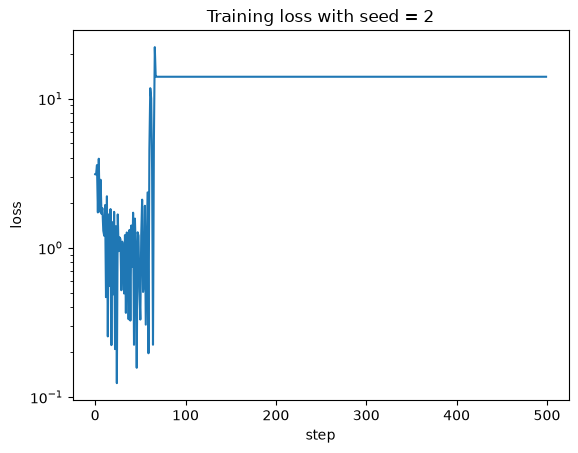

In [116]:
# Demo of not using zero grad
random.seed(2)
nn = MLP(3, [4,4,1])
history = train(nn, zero_grad=False)
print(history[0], history[49], history[-1])

g.plot(history)
g.yscale('log')
g.xlabel('step')
g.ylabel('loss')
g.title('Training loss with seed = 2')
g.show()

In [117]:
print(history[-1])

14.0


In [118]:
ys

[1.0, 3.0, 0.0, 2.0, 0.0]

When network predicts 0 for every input (5 inputs)
then loss is exactly 14.
But this means network died!
ypred = [0,0,0,0,0]

1 - 0 = 1
3 - 0 = 3
0 - 0
2 - 0 = 2
0 - 0

= 14

3.1083402277484544 0.7571822444318534 0.009708130148548488


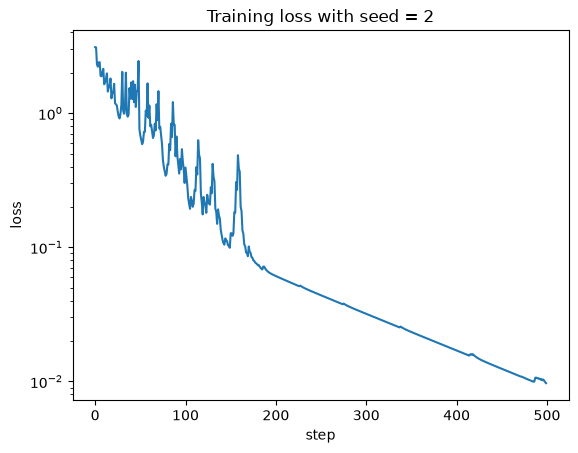

In [119]:
random.seed(2)
nn = MLP(3, [4,4,1])
history = train(nn, zero_grad=True)
print(history[0], history[49], history[-1])

g.plot(history)
g.yscale('log')
g.xlabel('step')
g.ylabel('loss')
g.title('Training loss with seed = 2')
g.show()

In [120]:
# Predictions on training data (Inference from the model)
# nn = already contains weights that are correct / give close-to-zero loss
print(f"{'input':>18} {'actual':>7} {'pred':>7}")
for x, y in zip(xs, ys):
    print(f"{str(x):>18} {y:7.2f} {nn(x).value:7.3f}")

             input  actual    pred
   [3.0, 1.0, 1.0]    1.00   0.929
   [4.0, 1.0, 0.0]    3.00   3.018
   [2.0, 2.0, 1.0]    0.00   0.032
   [5.0, 2.0, 1.0]    2.00   2.054
   [1.0, 0.0, 2.0]    0.00   0.024


In [121]:
# Predictions on unseen data
# 4 X 3   3 X 4
tests = [
    [6.0, 1.0, 2.0], # 3
    [2.0, 3.0, 0.0], # 0 
    [7.0, 2.0, 1.0], # 4
    [3.0, 0.0, 0.0]  # 3
]
print(f"{'input':>18} {'actual':>7} {'pred':>7}")
for x in tests:
    y_true = max(0, x[0] - x[1] - x[2])
    print(f"{str(x):>18} {y_true:7.2f} {nn(x).value:7.3f}")


             input  actual    pred
   [6.0, 1.0, 2.0]    3.00   2.209
   [2.0, 3.0, 0.0]    0.00   0.550
   [7.0, 2.0, 1.0]    4.00   4.175
   [3.0, 0.0, 0.0]    3.00   2.132


## Random seed

Random number generation:
Randomness -> Certainty | Pattern asto

Randomization : PhD

!!!! Pseudo random number generator is deterministic !!!

In [122]:
import random
# seed = seed of plant => plant chi quality 
random.seed(0)
for _ in range(3):
    print(random.uniform(-1,1))

0.6888437030500962
0.515908805880605
-0.15885683833831


In [123]:
random.seed(0)
for _ in range(3):
    print(random.uniform(-1,1))

0.6888437030500962
0.515908805880605
-0.15885683833831


In [86]:
random.seed(2)
for _ in range(3):
    print(random.uniform(-1,1))

0.9120685437784988
0.8956549741186988
-0.8868972645463826


## Dead neuron

ReLU 
derivative is 0 if value is negative
derivative is 1 if value is positive

If neuron's value is 0 then it is of no use in training
because it passes 0 gradient for every input.

In [124]:
def dead_neurons(model):
    alive = {id(n): False for layer in model.layers for n in layer.neurons}
    for x in xs:
        model(x)                              # forward pass fills last_pre
        for layer in model.layers:
            for n in layer.neurons:
                if n.last_pre > 0:
                    alive[id(n)] = True       # fired at least once
    return [sum(not alive[id(n)] for n in layer.neurons) for layer in model.layers]


def experiment(title, seeds=range(10), lr=0.01, steps=500, **mlp_kwargs):
    print(f"\n=== {title} ===")
    for seed in seeds:
        random.seed(seed)
        model = MLP(3, [4, 4, 1], **mlp_kwargs)
        dead_before = dead_neurons(model)
        history = train(model, lr=lr, epochs=steps)
        print(f"seed {seed:2d}  loss {history[-1]:8.4f}  "
              f"dead before {dead_before}  after {dead_neurons(model)}")

In [91]:
experiment("Simple ReLU everywhere lr = 0.01")


=== Simple ReLU everywhere lr = 0.01 ===
seed  0  loss  14.0000  dead before [1, 0, 0]  after [1, 0, 1]
seed  1  loss   0.0149  dead before [1, 3, 0]  after [1, 2, 0]
seed  2  loss   0.0097  dead before [0, 2, 0]  after [0, 2, 0]
seed  3  loss   0.0000  dead before [1, 1, 0]  after [1, 1, 0]
seed  4  loss   0.0039  dead before [2, 0, 0]  after [2, 1, 0]
seed  5  loss  14.0000  dead before [0, 3, 0]  after [1, 3, 0]
seed  6  loss   6.8000  dead before [1, 1, 0]  after [1, 4, 0]
seed  7  loss   0.0134  dead before [3, 2, 0]  after [3, 1, 0]
seed  8  loss   0.0016  dead before [1, 2, 0]  after [1, 2, 0]
seed  9  loss   0.0000  dead before [1, 2, 0]  after [2, 2, 0]


In [92]:
experiment("Simple ReLU everywhere lr = 0.1", lr=0.1)


=== Simple ReLU everywhere lr = 0.1 ===
seed  0  loss  14.0000  dead before [1, 0, 0]  after [4, 4, 1]
seed  1  loss   6.8000  dead before [1, 3, 0]  after [3, 4, 0]
seed  2  loss  14.0000  dead before [0, 2, 0]  after [4, 3, 1]
seed  3  loss  14.0000  dead before [1, 1, 0]  after [4, 2, 1]
seed  4  loss  14.0000  dead before [2, 0, 0]  after [4, 4, 1]
seed  5  loss  14.0000  dead before [0, 3, 0]  after [4, 3, 1]
seed  6  loss  14.0000  dead before [1, 1, 0]  after [4, 2, 1]
seed  7  loss  14.0000  dead before [3, 2, 0]  after [4, 4, 1]
seed  8  loss  14.0000  dead before [1, 2, 0]  after [4, 3, 1]
seed  9  loss  14.0000  dead before [1, 2, 0]  after [2, 2, 1]


In [93]:
experiment("Simple ReLU everywhere lr = 0.003", lr=0.003)


=== Simple ReLU everywhere lr = 0.003 ===
seed  0  loss   0.0832  dead before [1, 0, 0]  after [1, 0, 0]
seed  1  loss   0.0510  dead before [1, 3, 0]  after [1, 2, 0]
seed  2  loss   0.0874  dead before [0, 2, 0]  after [0, 2, 0]
seed  3  loss   0.0002  dead before [1, 1, 0]  after [1, 1, 0]
seed  4  loss   0.0036  dead before [2, 0, 0]  after [2, 1, 0]
seed  5  loss   0.0055  dead before [0, 3, 0]  after [0, 1, 0]
seed  6  loss   0.0012  dead before [1, 1, 0]  after [1, 1, 0]
seed  7  loss   0.0109  dead before [3, 2, 0]  after [3, 1, 0]
seed  8  loss   0.0019  dead before [1, 2, 0]  after [1, 2, 0]
seed  9  loss   0.0039  dead before [1, 2, 0]  after [2, 2, 0]


In [125]:
experiment("Simple ReLU everywhere lr = 0.003", lr=0.01, steps=500, initial_bias=0.1)


=== Simple ReLU everywhere lr = 0.003 ===
seed  0  loss  14.0000  dead before [1, 1, 0]  after [4, 2, 1]
seed  1  loss  14.0000  dead before [2, 1, 0]  after [2, 1, 0]
seed  2  loss  14.0000  dead before [0, 1, 1]  after [0, 1, 1]
seed  3  loss   0.0099  dead before [2, 0, 0]  after [2, 2, 0]
seed  4  loss  14.0000  dead before [3, 1, 1]  after [3, 1, 1]
seed  5  loss   6.8000  dead before [0, 4, 0]  after [0, 4, 0]
seed  6  loss  14.0000  dead before [0, 2, 1]  after [0, 2, 1]
seed  7  loss   6.8000  dead before [3, 0, 0]  after [4, 2, 0]
seed  8  loss   6.8000  dead before [1, 4, 0]  after [1, 4, 0]
seed  9  loss  14.0000  dead before [1, 0, 1]  after [1, 0, 1]


bias of 0.1 is fixed and not random at all!!

weights are in (-1, 1) but bias is always 0.1
sum of all xi * wi is almost always > 10 (5 inputs)

Sometimes due to random bias, some neurons are kept alive.
That is not the case anymore.

## Assignment:
Implement Leaky ReLU and improve this training!

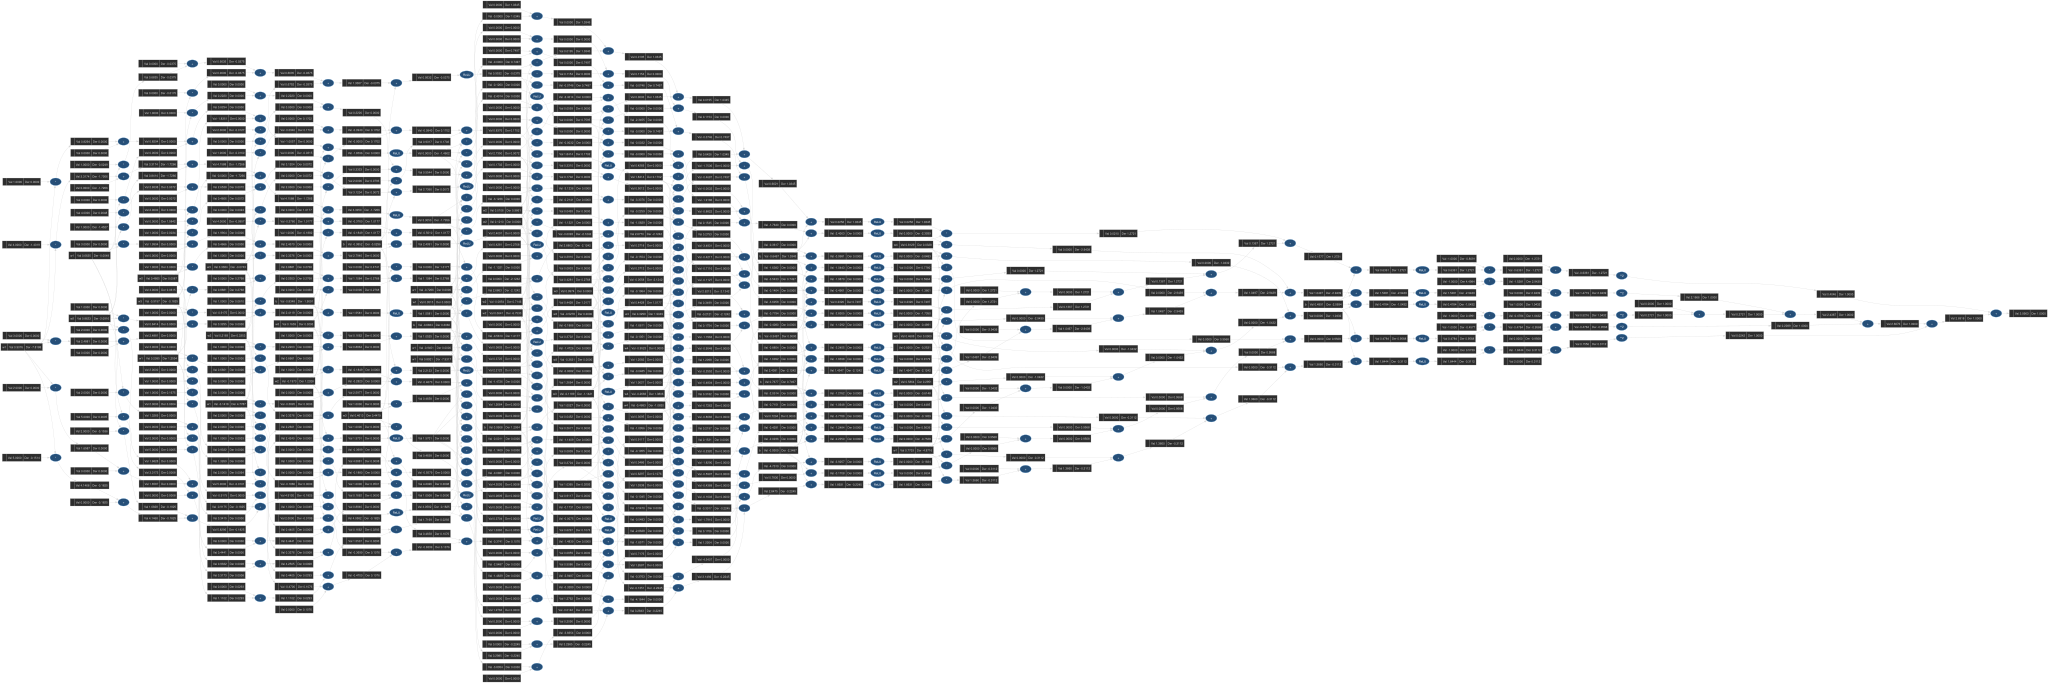

In [126]:
draw_graph(loss)